In [ ]:
# ==========================================
# 1.IMPORT LIBRARY
# ==========================================
import stanza
import pandas as pd
from pathlib import Path
from IPython.display import display

print("Library Stanza dan pandas berhasil diimpor.")

Library Stanza dan pandas berhasil diimpor.


In [11]:
# ==========================================
# 2. MEMUAT MODEL STANZA BAHASA INDONESIA
# ==========================================
stanza.download("id")

nlp = stanza.Pipeline(
    lang="id",
    processors="tokenize,pos,lemma,depparse",
    verbose=False,
)
print("Model Stanza Bahasa Indonesia berhasil dimuat.")

2026-10-24 09:08:12 INFO: Downloaded file to C:\Users\ASUS\AppData\Local\StanfordNLP\stanza\Cache\1.15.0\resources\resources.json
2026-10-24 09:08:12 INFO: Downloading default packages for language: id (Indonesian) ...
2026-10-24 09:08:19 INFO: File exists: C:\Users\ASUS\AppData\Local\StanfordNLP\stanza\Cache\1.15.0\resources\id\default.zip
2026-10-24 09:08:40 INFO: Finished downloading models and saved to C:\Users\ASUS\AppData\Local\StanfordNLP\stanza\Cache\1.15.0\resources


Model Stanza Bahasa Indonesia berhasil dimuat.


In [12]:
# ==========================================
# 3. MEMPROSES KALIMAT
# ==========================================
doc = nlp("Mahasiswa belajar Natural Language Processing.")

for sentence in doc.sentences:
    for word in sentence.words:
        print(f"{word.text:<15} {word.upos:<10} {word.deprel}")

Mahasiswa       PROPN      nsubj
belajar         VERB       root
Natural         PROPN      obj
Language        PROPN      flat:name
Processing      PROPN      flat:name
.               PUNCT      punct


In [4]:
# ==========================================
# 4. ANALISIS POS TOKEN
# ==========================================
doc = nlp("Mahasiswa belajar Natural Language Processing.")

print(f"{'Token':<15} {'POS':<10} {'Lemma'}")
print("-" * 40)
for sentence in doc.sentences:
    for word in sentence.words:
        print(f"{word.text:<15} {word.upos:<10} {word.lemma}")

Token           POS        Lemma
----------------------------------------
Mahasiswa       PROPN      mahasiswa
belajar         VERB       belajar
Natural         PROPN      natural
Language        PROPN      language
Processing      PROPN      processing
.               PUNCT      .


In [5]:
# ==========================================
# 5. MEMBUAT TABEL ANALISIS POS
# ==========================================
def analyze_pos(text, nlp_model):
    doc = nlp_model(text)
    results = []
    for sentence in doc.sentences:
        words_by_id = {word.id: word.text for word in sentence.words}
        for word in sentence.words:
            head = "ROOT" if word.head == 0 else words_by_id.get(word.head, "?")
            results.append({
                "Token": word.text,
                "POS": word.upos,
                "POS Tag": word.xpos,
                "Lemma": word.lemma,
                "Dependency": word.deprel,
                "Head": head
            })
    return pd.DataFrame(results)

df_pos = analyze_pos("Mahasiswa belajar NLP.", nlp)
display(df_pos)

,Token,POS,POS Tag,Lemma,Dependency,Head
0,Mahasiswa,PROPN,NSD,mahasiswa,nsubj,belajar
1,belajar,VERB,NSD,belajar,root,ROOT
2,NLP,PROPN,X--,nlp,obj,belajar
3,.,PUNCT,Z--,.,punct,belajar


In [6]:
# ==========================================
# 6. ANALISIS BEBERAPA KALIMAT
# ==========================================
sentences = [
    "Mahasiswa belajar NLP.",
    "Dosen mengajar Natural Language Processing.",
    "Mahasiswa membaca buku.",
    "Sistem memproses data teks.",
    "Model bahasa memprediksi kata berikutnya."
]

for sentence in sentences:
    print(f"\nKalimat: {sentence}")
    df_result = analyze_pos(sentence, nlp)
    display(df_result[["Token", "POS", "Dependency", "Head"]].reset_index(drop=True))


Kalimat: Mahasiswa belajar NLP.


,Token,POS,Dependency,Head
0,Mahasiswa,PROPN,nsubj,belajar
1,belajar,VERB,root,ROOT
2,NLP,PROPN,obj,belajar
3,.,PUNCT,punct,belajar



Kalimat: Dosen mengajar Natural Language Processing.


,Token,POS,Dependency,Head
0,Dosen,PROPN,nsubj,mengajar
1,mengajar,VERB,root,ROOT
2,Natural,PROPN,obj,mengajar
3,Language,PROPN,flat:name,Natural
4,Processing,PROPN,flat:name,Language
5,.,PUNCT,punct,mengajar



Kalimat: Mahasiswa membaca buku.


,Token,POS,Dependency,Head
0,Mahasiswa,PROPN,nsubj,membaca
1,membaca,VERB,root,ROOT
2,buku,NOUN,obj,membaca
3,.,PUNCT,punct,membaca



Kalimat: Sistem memproses data teks.


,Token,POS,Dependency,Head
0,Sistem,PROPN,nsubj,memproses
1,memproses,VERB,root,ROOT
2,data,NOUN,obj,memproses
3,teks,NOUN,compound,data
4,.,PUNCT,punct,memproses



Kalimat: Model bahasa memprediksi kata berikutnya.


,Token,POS,Dependency,Head
0,Model,NOUN,nsubj,memprediksi
1,bahasa,NOUN,compound,Model
2,memprediksi,VERB,root,ROOT
3,kata,NOUN,obj,memprediksi
4,berikutnya,ADJ,amod,kata
5,.,PUNCT,punct,memprediksi


In [7]:
# ==========================================
# 7. DEPENDENCY PARSING
# ==========================================
doc = nlp("Mahasiswa belajar NLP.")

print(f"{'Token':<15} {'Dep':<12} {'Head'}")
print("-" * 40)
for sentence in doc.sentences:
    words_by_id = {word.id: word.text for word in sentence.words}
    for word in sentence.words:
        head = "ROOT" if word.head == 0 else words_by_id.get(word.head, "?")
        print(f"{word.text:<15} {word.deprel:<12} {head}")

Token           Dep          Head
----------------------------------------
Mahasiswa       nsubj        belajar
belajar         root         ROOT
NLP             obj          belajar
.               punct        belajar


In [8]:
# ==========================================
# 8. VISUALISASI DEPENDENCY
# ==========================================
doc = nlp("Mahasiswa belajar Natural Language Processing.")
dependency_results = analyze_pos("Mahasiswa belajar Natural Language Processing.", nlp)
display(dependency_results[["Token", "Dependency", "Head"]])

# Simpan hasil dependency parsing sebagai tabel HTML.
html_path = Path("dependency_tree.html")
html_path.write_text(
    dependency_results[["Token", "Dependency", "Head"]].to_html(index=False),
    encoding="utf-8",
)
print("Tabel dependency disimpan di:", html_path.resolve())

,Token,Dependency,Head
0,Mahasiswa,nsubj,belajar
1,belajar,root,ROOT
2,Natural,obj,belajar
3,Language,flat:name,Natural
4,Processing,flat:name,Language
5,.,punct,belajar


Tabel dependency disimpan di: D:\Semester 5\NLP\modul-1\dependency_tree.html


In [ ]:
# ==========================================
# 9. ANALISIS DATASET
# ==========================================
dataset_candidates = [
    Path.cwd() / "dataset_preprocessed.csv",
    Path.cwd().parent / "dataset_preprocessed.csv",
    Path.cwd() / "MBG_Arya.csv",
    Path.cwd().parent / "MBG_Arya.csv",
]
dataset_path = next((path for path in dataset_candidates if path.is_file()), None)
if dataset_path is None:
    raise FileNotFoundError("Dataset tidak ditemukan. Pastikan dataset_preprocessed.csv atau MBG_Arya.csv ada di folder proyek.")
df = pd.read_csv(dataset_path)
text_column = "clean_text"  

# Ambil sample untuk analisis
sample = df.sample(10, random_state=42)

for _, row in sample.iterrows():
    text = str(row[text_column])[:200]  
    doc = nlp(text)
    pos_counts = {}
    for sentence in doc.sentences:
        for word in sentence.words:
            pos_counts[word.upos] = pos_counts.get(word.upos, 0) + 1
    print(f"Teks: {text[:80]}...")
    print(f"POS Distribution: {pos_counts}")
    print()

Teks: heti kus endang dn pa dedi...
POS Distribution: {'PROPN': 1, 'NOUN': 5}

Teks: otak korup yang udah mendarah daging memang sulit untuk tidak ngiler ketika meli...
POS Distribution: {'NOUN': 5, 'ADJ': 2, 'PRON': 1, 'ADV': 2, 'VERB': 3, 'SCONJ': 2, 'PART': 1}

Teks: masih bs ketawa ya...
POS Distribution: {'ADV': 1, 'NOUN': 1, 'VERB': 1, 'PART': 1}

Teks: korupsi berkedok proyek mbg korupsi yang dilegalkan oleh kebijakan program mbg...
POS Distribution: {'NOUN': 6, 'VERB': 2, 'PRON': 1, 'ADP': 1, 'PROPN': 1}

Teks: ayo kita bahas bagaimana cara agar proyek unggulan mbg dan kdmp ini segera dihen...
POS Distribution: {'ADV': 3, 'PRON': 1, 'VERB': 2, 'NOUN': 6, 'SCONJ': 1, 'CCONJ': 1, 'DET': 1, 'ADP': 1}

Teks: entah apa tujuan pk prabowo ngasih makan gratis kpd semua siswa baik dari keluar...
POS Distribution: {'VERB': 5, 'PRON': 2, 'NOUN': 8, 'ADJ': 5, 'DET': 1, 'ADP': 2}

Teks: kau tdk seharusnya sedih tp seharusnya kau malu dan mundur krn program yg kau bu...
POS Distribution: {'P

In [10]:
# ==========================================
# 10. ANALISIS KESALAHAN
# ==========================================
informal_texts = [
    "aku lg belajar NLP nih",
    "gue udah baca buku itu",
    "modelnya bagus bgt sih",
    "nggak ngerti sama sekali",
    "udah instal belum?"
]

print("Analisis Teks Informal:")
print("=" * 60)
for text in informal_texts:
    doc = nlp(text)
    print(f"\nTeks: {text}")
    for sentence in doc.sentences:
        for word in sentence.words:
            print(f"  {word.text:<15} {word.upos}")

Analisis Teks Informal:

Teks: aku lg belajar NLP nih
  aku             PRON
  lg              VERB
  belajar         VERB
  NLP             PROPN
  nih             NOUN

Teks: gue udah baca buku itu
  gue             PROPN
  udah            ADV
  baca            VERB
  buku            NOUN
  itu             DET

Teks: modelnya bagus bgt sih
  model           NOUN
  nya             PRON
  bagus           ADJ
  bgt             X
  sih             NOUN

Teks: nggak ngerti sama sekali
  nggak           PART
  ngerti          VERB
  sama            ADJ
  sekali          ADV

Teks: udah instal belum?
  udah            X
  instal          VERB
  belum           PART
  ?               PUNCT


## E. Tugas Analisis Linguistik

Analisis 10 kalimat dari dataset menggunakan tokenisasi, POS tagging, dan dependency parsing. Tabel menampilkan hasil per token. Nilai pada kolom **Kesalahan?** perlu ditinjau dan diisi secara manual dengan membandingkan prediksi Stanza terhadap kalimat asli; keluaran model tidak otomatis membuktikan bahwa analisisnya benar atau salah. Diagram dependency ditampilkan untuk setiap kalimat.

In [17]:
# ==========================================
# 11.1 PERSIAPAN DATA 10 KALIMAT
# ==========================================
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
from IPython.display import display
from matplotlib.path import Path as PlotPath
from matplotlib.patches import FancyArrowPatch

dataset_candidates = [
    Path.cwd() / "dataset_preprocessed.csv",
    Path.cwd().parent / "dataset_preprocessed.csv",
    Path.cwd() / "MBG_Arya.csv",
    Path.cwd().parent / "MBG_Arya.csv",
]
dataset_path = next((path for path in dataset_candidates if path.is_file()), None)
if dataset_path is None:
    raise FileNotFoundError(
        "Dataset tidak ditemukan. Letakkan dataset_preprocessed.csv atau MBG_Arya.csv "
        "di folder proyek atau folder induknya."
    )
df = pd.read_csv(dataset_path)

if "nlp" not in globals():
    import stanza
    stanza.download("id")
    nlp = stanza.Pipeline(
        lang="id",
        processors="tokenize,pos,lemma,depparse",
        verbose=False,
    )

analysis_column = "text_original" if "text_original" in df.columns else "clean_text"
analysis_candidates = df[analysis_column].dropna().astype(str).str.strip()
analysis_candidates = analysis_candidates[analysis_candidates.ne("")]
# Hilangkan duplikat dokumen setelah merapikan spasi dan mengabaikan kapitalisasi.
analysis_candidates = analysis_candidates.loc[
    ~analysis_candidates.map(lambda text: " ".join(text.casefold().split())).duplicated()
]
if len(analysis_candidates) < 10:
    raise ValueError(
        f"Dibutuhkan minimal 10 teks unik, tetapi hanya tersedia {len(analysis_candidates)}."
    )

# Acak seluruh dokumen unik, bukan hanya sampel kecil yang bisa berisi duplikat kalimat.
sampled_texts = analysis_candidates.sample(frac=1, random_state=42).tolist()
selected_sentences = []
seen_sentences = set()
for text in sampled_texts:
    parsed_doc = nlp(text)
    for parsed_sentence in parsed_doc.sentences:
        if not parsed_sentence.words:
            continue
        sentence_key = " ".join(parsed_sentence.text.casefold().split())
        if sentence_key in seen_sentences:
            continue
        seen_sentences.add(sentence_key)
        selected_sentences.append(parsed_sentence)
        if len(selected_sentences) == 10:
            break
    if len(selected_sentences) == 10:
        break

if len(selected_sentences) < 10:
    raise ValueError(
        f"Hanya ditemukan {len(selected_sentences)} kalimat unik yang dapat dianalisis; "
        "periksa jumlah teks unik pada dataset."
    )
print(f"Siap menganalisis {len(selected_sentences)} kalimat unik dari {dataset_path.name}.")
for sentence_number, parsed_sentence in enumerate(selected_sentences, start=1):
    print(f"{sentence_number}. {parsed_sentence.text}")


Siap menganalisis 10 kalimat unik dari dataset_preprocessed.csv.
1. Bang, sy on progres bangun dapur MBG. Mau lah dapur sy nanti jadi project bareng.
2. bang Raymond pasti tau, mau dibahas sampe kapan pun gak bakal bener negara ni.
3. alasannya karena sejak awal populasi sudah tidak merata, dsni monopoli kekuasaan mereka.
4. 1 pulau Kalimantan = 20jt org, 1 pulau sulawesi = 20 jt orang, 1 pulau papua =20 jt orang, tapi 1 provinsi Jawa barat saja 50 jt orang.
5. jadi gak adil dong?
6. ya emang...ini ilusi demokrasi kita yg gak akan berani dibahas oleh konten2 kreator politik.
7. monopoli kekuasaan akan berputar disitu2 saja, menteri2 boneka, proyek bagi2 kue, janji 19 jt lapangan voli, mw dibahas jg cman jadi paradox yg akan selalu terulang kembali sampe kita ubanan, punya cucu, terus masuk liang lahat.
8. Kabari kalau hukuman mati buat koruptor sudah berlaku
9. kacung2 nya saja ini
10. Stop dan stop stop stop stop stop MBG program beracun yang sudah merenggut puluh ribu nyawa manusia a

In [29]:
# ==========================================
# 11.2 TABEL HASIL ANALISIS
# ==========================================
# Satu baris per kalimat agar tabel tidak tampak seperti mengulang kalimat.
# Catatan analisis manual berdasarkan hasil yang sudah diperiksa.
# Beberapa label (mis. PROPN/PRON atau DET/PRON) tetap bergantung pada konteks.
manual_error_notes = {
    1: (
        '"sy" merupakan singkatan informal "saya" dan seharusnya PRON. '
        'Periksa kembali label "Bang" sesuai konteks sapaan/nama. '
        'Relasi koma sebagai punct perlu mengarah ke token yang tepat, bukan menjadikan "sy" sebagai punct.'
    ),
    2: (
        'Periksa label "bang" yang menjadi PROPN; huruf kecil tidak otomatis menentukan kelas katanya. '
        'Relasi flat:name pada "bang Raymond" perlu ditinjau arah head-nya; jika "bang" sapaan, analisis flat/appos dapat berbeda.'
    ),
    3: (
        'Pada frasa "sejak awal", "awal" lebih sesuai dianalisis sebagai nomina (NOUN), bukan adjective (ADJ). '
        'Pemisahan "alasan" dan "nya" sudah sesuai dengan hasil yang dilaporkan.'
    ),
    4: (
        'Token "20jt" sebaiknya diperiksa karena angka dan singkatan "jt" dapat perlu dipisahkan menjadi NUM + NOUN. '
        'Label simbol "=" juga perlu dibandingkan dengan konvensi anotasi yang digunakan.'
    ),
    5: (
        '"dong" berfungsi sebagai partikel penegas (PART; bergantung panduan anotasi). '
        'Label/relasi "adil" dan "jadi" perlu ditinjau berdasarkan fungsi dalam konteks; '
        'jangan simpulkan root hanya dari kelas katanya.'
    ),
    6: (
        '"emang" adalah bentuk informal "memang"; dalam konteks ini lebih mungkin ADV atau PART daripada VERB.'
    ),
    7: (
        '"disitu2" adalah bentuk informal/tidak baku dan tokennya perlu ditinjau. '
        'Normalisasi menjadi "di situ-situ" atau bentuk sesuai konteks dapat membantu; '
        'jangan langsung menetapkan POS tanpa melihat kalimat lengkap.'
    ),
    8: (
        '"Kabari" tampaknya kata kerja imperatif (VERB), bukan PROPN. Kapitalisasi di awal kalimat '
        'kemungkinan membuat model salah mengira sebagai nama diri.'
    ),
    9: (
        '"ini" dapat berlabel DET jika menerangkan nomina atau PRON jika berdiri sendiri sebagai penunjuk; '
        'periksa fungsi sintaksisnya dalam kalimat.'
    ),
    10: (
        '"Stop/stop" tampaknya dipakai sebagai perintah atau interjeksi, bukan PROPN/NOUN. '
        'Tentukan label yang konsisten menurut konteks dan panduan anotasi.'
    ),
}
analysis_rows = []
for sentence_number, parsed_sentence in enumerate(selected_sentences, start=1):
    words_by_id = {word.id: word.text for word in parsed_sentence.words}
    tokens = [word.text for word in parsed_sentence.words]
    pos_tags = [word.upos for word in parsed_sentence.words]
    dependencies = [
        f"{word.deprel} -> {'ROOT' if word.head == 0 else words_by_id.get(word.head, 'Tidak diketahui')}"
        for word in parsed_sentence.words
    ]
    analysis_rows.append({
        "No.": sentence_number,
        "Kalimat": parsed_sentence.text,
        "Token": " | ".join(tokens),
        "POS": " | ".join(pos_tags),
        "Dependency": " | ".join(dependencies),
        "Kesalahan?": manual_error_notes.get(
            sentence_number, "Belum ditinjau manual; cek hasil parser terhadap konteks kalimat"
        ),
    })

analysis_table = pd.DataFrame(analysis_rows)
assert analysis_table["Kalimat"].nunique() == len(selected_sentences), (
    "Kalimat yang dipilih tidak unik. Jalankan ulang sel persiapan."
)
display(analysis_table)


,No.,Kalimat,Token,POS,Dependency,Kesalahan?
0,1,"Bang, sy on progres bangun dapur MBG. Mau lah ...","Bang | , | sy | on | progres | bangun | dapur ...",PROPN | PUNCT | PROPN | PROPN | NOUN | VERB | ...,nsubj -> bangun | punct -> sy | flat:name -> B...,"""sy"" merupakan singkatan informal ""saya"" dan s..."
1,2,"bang Raymond pasti tau, mau dibahas sampe kapa...","bang | Raymond | pasti | tau | , | mau | dibah...",PROPN | PROPN | ADV | VERB | PUNCT | AUX | VER...,nsubj -> tau | flat:name -> bang | advmod -> t...,"Periksa label ""bang"" yang menjadi PROPN; huruf..."
2,3,alasannya karena sejak awal populasi sudah tid...,alasan | nya | karena | sejak | awal | populas...,NOUN | PRON | SCONJ | ADP | ADJ | NOUN | AUX |...,root -> ROOT | nmod:poss -> alasan | mark -> m...,"Pada frasa ""sejak awal"", ""awal"" lebih sesuai d..."
3,4,"1 pulau Kalimantan = 20jt org, 1 pulau sulawes...","1 | pulau | Kalimantan | = | 20jt | org | , | ...",NUM | NOUN | PROPN | SYM | NOUN | NOUN | PUNCT...,nummod -> pulau | root -> ROOT | nmod -> pulau...,"Token ""20jt"" sebaiknya diperiksa karena angka ..."
4,5,jadi gak adil dong?,jadi | gak | adil | dong | ?,VERB | PART | ADJ | NOUN | PUNCT,root -> ROOT | advmod -> adil | amod -> jadi |...,"""dong"" berfungsi sebagai partikel penegas (PAR..."
5,6,ya emang...ini ilusi demokrasi kita yg gak aka...,ya | emang | . | ..ini | ilusi | demokrasi | k...,PART | VERB | PUNCT | PUNCT | NOUN | NOUN | PR...,advmod -> emang | root -> ROOT | punct -> eman...,"""emang"" adalah bentuk informal ""memang""; dalam..."
6,7,"monopoli kekuasaan akan berputar disitu2 saja,...",monopoli | kekuasaan | akan | berputar | disit...,NOUN | NOUN | AUX | VERB | NOUN | ADV | PUNCT ...,nsubj -> berputar | compound -> monopoli | aux...,"""disitu2"" adalah bentuk informal/tidak baku da..."
7,8,Kabari kalau hukuman mati buat koruptor sudah ...,Kabari | kalau | hukuman | mati | buat | korup...,PROPN | SCONJ | NOUN | ADJ | ADP | NOUN | AUX ...,nsubj -> berlaku | mark -> berlaku | nsubj -> ...,"""Kabari"" tampaknya kata kerja imperatif (VERB)..."
8,9,kacung2 nya saja ini,kacung2 | nya | saja | ini,NOUN | PRON | ADV | DET,root -> ROOT | nmod:poss -> kacung2 | advmod -...,"""ini"" dapat berlabel DET jika menerangkan nomi..."
9,10,Stop dan stop stop stop stop stop MBG program ...,Stop | dan | stop | stop | stop | stop | stop ...,PROPN | CCONJ | NOUN | NOUN | NOUN | NOUN | NO...,root -> ROOT | cc -> stop | conj -> Stop | com...,"""Stop/stop"" tampaknya dipakai sebagai perintah..."


In [31]:
# ==========================================
# 11.3 FUNGSI VISUALISASI DEPENDENCY TREE
# ==========================================
def plot_dependency_tree(parsed_sentence, sentence_number):
    words = parsed_sentence.words
    positions = {word.id: index for index, word in enumerate(words)}
    figure_width = max(9, min(22, len(words) * 0.75))
    fig, ax = plt.subplots(figsize=(figure_width, 4.8))

    for index, word in enumerate(words):
        ax.text(
            index, 0, word.text, ha="center", va="center", fontsize=10,
            bbox={"boxstyle": "round,pad=0.3", "facecolor": "#eaf2f8", "edgecolor": "#5d6d7e"},
        )
        ax.text(index, -0.42, word.upos, ha="center", va="center", fontsize=8, color="#34495e")
        if word.head == 0:
            ax.text(index, 0.62, "ROOT", ha="center", va="bottom", fontsize=8, color="#922b21")
            continue

        head_index = positions.get(word.head)
        if head_index is None:
            continue
        height = 0.85 + abs(index - head_index) * 0.22
        curve = PlotPath(
            [(head_index, 0.16), (head_index, height), (index, height), (index, 0.16)],
            [PlotPath.MOVETO, PlotPath.CURVE4, PlotPath.CURVE4, PlotPath.CURVE4],
        )
        ax.add_patch(FancyArrowPatch(
            path=curve, arrowstyle="-|>", mutation_scale=9, linewidth=1,
            color="#2874a6", shrinkA=4, shrinkB=4,
        ))
        ax.text(
            (head_index + index) / 2, height + 0.05, word.deprel,
            ha="center", va="bottom", fontsize=8, color="#1b4f72",
        )

    ax.set_title(f"Dependency Tree Kalimat {sentence_number}: {parsed_sentence.text}", fontsize=10)
    ax.set_xlim(-0.6, len(words) - 0.4)
    ax.set_ylim(-0.75, max(1.5, len(words) * 0.22 + 1.2))
    ax.axis("off")
    fig.tight_layout()
    display(fig)
    plt.close(fig)


contoh kalimat: jadi gak adil dong?


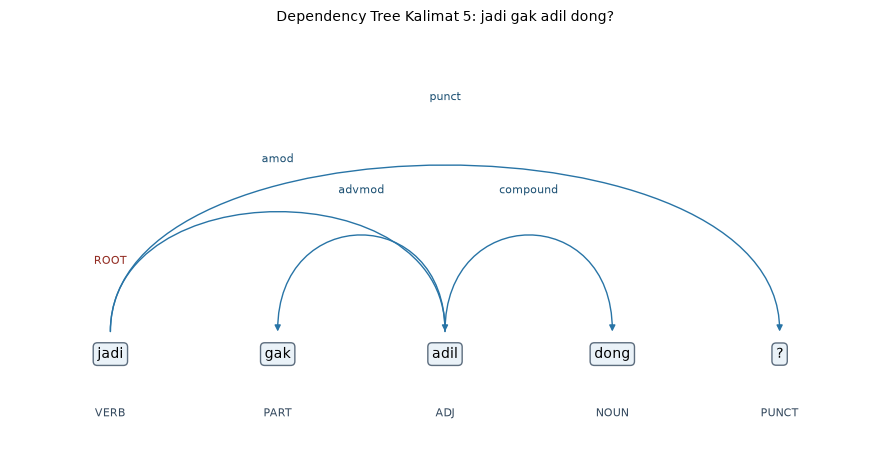

In [28]:
# ==========================================
# 11.4.5 DEPENDENCY TREE
# ==========================================
print("contoh kalimat:", selected_sentences[4].text)
plot_dependency_tree(selected_sentences[4], 5)
